# Simulator walkthrough
One section per step of the `sim` rebuild. Each section shows what that step added, using the
functions as they exist at that step. Run the cells top to bottom.

**To run it** (from this repo's root, in bash or PowerShell), then open the `127.0.0.1` link it prints:
```bash
docker run --rm -it -p 8888:8888 -v "${PWD}:/gtc" -w /gtc -e UV_PROJECT_ENVIRONMENT=/tmp/venv \
    ogdenm12/gtc-base-image:v2 uv run --group notebook jupyter lab --ip=0.0.0.0 --allow-root --no-browser
```
- `-v "${PWD}:/gtc"` mounts this repo into the container, so edits on Windows show up immediately.
- `UV_PROJECT_ENVIRONMENT=/tmp/venv` keeps the Linux virtual environment inside the container, out of the repo.
  It's rebuilt each time the container starts (a minute or two, mostly compiling SPAM).
- Our package is installed in editable mode. After editing a `.py` file, restart the kernel to pick it up.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from galactic_tidal_constraints.simr import sim

## Step 1: one SPAM run
`sim.simulate(params, n1, n2)` passes the 22 parameters to `jspam.run_collision` and returns the final
state of every particle.

The 22 values are SPAM's model string. In order: the secondary's position and velocity relative to the
primary (x, y, z, vx, vy, vz), the two masses, the two disk radii, the two disks' orientations (phi, theta),
two softening values, and six r-scale values (all 0 here).

This model is SDSS 587722984435351614, from JSPAM's `archive/data.txt`.

In [4]:
MODEL = [
    -9.93853, -4.5805, 15.43348, -1.54025, -2.97899, 4.69234, 34.41671, 29.49607, 2.97913, 4.2501, 301.0,
    35.5, 310.80745, 321.98757, 0.3, 0.3, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
]
N1, N2 = 2000, 2000

particles = sim.simulate(MODEL, n1=N1, n2=N2)
print("shape:", particles.shape)  # (N1 + N2 + 1, 6): one row per particle, plus the secondary's center
print("secondary's center (x, y, z, vx, vy, vz):", particles[-1])

shape: (4001, 6)
secondary's center (x, y, z, vx, vy, vz): [-9.94007008 -4.58347891 15.43817208 -1.5399158  -2.97883593  4.69182098]


Compare the secondary's center with the first six values of `MODEL`: they nearly match. The 22 values
describe the system *now*, as observed. SPAM first runs the two centers backward to find a start time
before the encounter, places the disks there, then runs everything forward and stops at about "now"
(a step or two past it). So a run ends at the observed moment, with the tidal features formed.

Next, split the rows into the two disks and plot x against y. The primary's center stays at the origin.

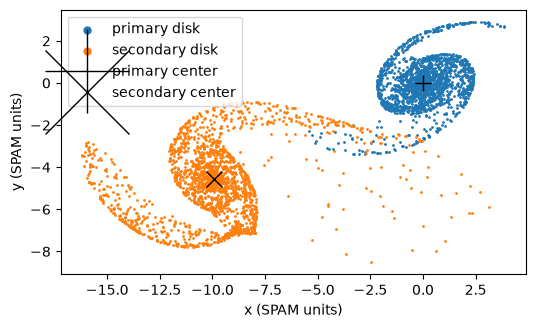

In [5]:
primary = particles[:N1]
secondary = particles[N1:N1 + N2]
center2 = particles[-1]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(primary[:, 0], primary[:, 1], s=1, label="primary disk")
ax.scatter(secondary[:, 0], secondary[:, 1], s=1, label="secondary disk")
ax.plot(0, 0, "k+", ms=12, label="primary center")
ax.plot(center2[0], center2[1], "kx", ms=12, label="secondary center")
ax.set_aspect("equal")
ax.set_xlabel("x (SPAM units)")
ax.set_ylabel("y (SPAM units)")
ax.legend(markerscale=5)
plt.show()

Run it again and compare. The disk particles start from unseeded random positions, so they differ every
run. The secondary's center doesn't depend on them, so it matches. Seeds come in step 3.

In [6]:
again = sim.simulate(MODEL, n1=N1, n2=N2)
print("secondary's center matches:", np.allclose(again[-1], particles[-1]))
print("disk particles match:      ", np.allclose(again[:-1], particles[:-1]))

secondary's center matches: True
disk particles match:       False
